# 6BUIS017W CWK1 – Task 1: Data Preparation and Feature Engineering
S&P 500, 1 Jan 2021 – 1 Jan 2025 (end exclusive).
The first run downloads data and saves it in data/. Later runs reload that snapshot, so results stay the same.
Code adapted from the tutorials: Week 3 (RFM_Yahoofin – high-volume rule), Week 4/5 (sp500 / SP500_RFM_Analysis –
Wikipedia tickers, weekly returns and beta functions) and Week 7 (resampling). Unlike the tutorials, missing prices are NOT filled.

In [1]:
# Install yfinance (pyarrow is used to save the raw data as a parquet file)
!pip install -q yfinance pyarrow

In [2]:
#Setup
import os, json, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Folders that will be uploaded to GitHub
for folder in ["data", "outputs", "figures"]:
    os.makedirs(folder, exist_ok=True)

# Study period from the brief. yfinance treats END as exclusive, so the last possible day is 31 Dec 2024
START = "2021-01-01"
END = "2025-01-01"
BENCHMARK = "^GSPC"

# Save package versions so the work can be reproduced
versions = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "matplotlib": matplotlib.__version__,
}
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'matplotlib': '3.10.0'}


## 1.1 Ticker selection and data acquisition
Tickers come from Wikipedia using pandas.read_html (same as the Week 4/5 tutorial). Dots are changed to dashes (BRK.B - BRK-B) for Yahoo.

In [3]:
#1.1a  S&P 500 ticker list
TICKER_FILE = "data/sp500_constituents.csv"
META_FILE = "data/metadata.json"

if os.path.exists(TICKER_FILE) and os.path.exists(META_FILE):
    # Re-use the saved list so the analysis can be repeated exactly
    sp500_df = pd.read_csv(TICKER_FILE)
    meta = json.load(open(META_FILE))
    print("Loaded saved ticker list, retrieved on:", meta["ticker_retrieval_date"])
else:
    url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    # User-Agent is needed or Wikipedia blocks the request (HTTP 403)
    table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
    sp500_df = table[0]
    sp500_df["yf_ticker"] = sp500_df["Symbol"].str.replace(".", "-", regex=False)
    sp500_df.to_csv(TICKER_FILE, index=False)
    meta = {
        "ticker_source": url,
        "ticker_retrieval_date": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
    }
    json.dump(meta, open(META_FILE, "w"), indent=2)
    print("Retrieved ticker list on:", meta["ticker_retrieval_date"])

tickers = sp500_df["yf_ticker"].tolist()
print("Tickers in the current constituent list:", len(tickers))
sp500_df[["Symbol", "yf_ticker", "Security", "GICS Sector", "Date added"]].head()

Retrieved ticker list on: 2026-11-21 06:47 UTC
Tickers in the current constituent list: 503


,Symbol,yf_ticker,Security,GICS Sector,Date added
0,MMM,MMM,3M,Industrials,1957-03-04
1,AOS,AOS,A. O. Smith,Industrials,2017-07-26
2,ABT,ABT,Abbott Laboratories,Health Care,1957-03-04
3,ABBV,ABBV,AbbVie,Health Care,2012-12-31
4,ACN,ACN,Accenture,Information Technology,2011-07-06


In [4]:
#1.1b  Download daily prices, adjusted prices, volume and ^GSPC
# I use yfinance because it's what the tutorials use, it's free, and one call gives
# Close, Adj Close, Volume, Dividends and Stock Splits (needed for corporate action checks)
RAW_FILE = "data/raw_daily_2021_2024.parquet"

def download_batch(symbols):
    # auto_adjust=False keeps both Close and Adj Close; actions=True adds dividends and splits
    return yf.download(symbols, start=START, end=END, auto_adjust=False, actions=True,
                       group_by="column", threads=True, progress=False)

if os.path.exists(RAW_FILE):
    raw = pd.read_parquet(RAW_FILE)
    print("Loaded cached raw snapshot:", RAW_FILE)
else:
    # Download in batches of 100 so Yahoo is less likely to block us
    parts = [download_batch(tickers[i:i + 100]) for i in range(0, len(tickers), 100)]
    parts.append(download_batch([BENCHMARK]))
    raw = pd.concat(parts, axis=1)

    # Retry once for any ticker that came back empty
    failed = [t for t in tickers if t not in raw["Adj Close"].columns or raw["Adj Close"][t].isna().all()]
    if failed:
        print("Retrying", len(failed), "tickers:", failed)
        retry = download_batch(failed)
        raw = raw.drop(columns=[c for c in raw.columns if c[1] in failed])
        raw = pd.concat([raw, retry], axis=1)

    raw = raw.sort_index().sort_index(axis=1)
    raw.to_parquet(RAW_FILE)
    meta["price_source"] = f"Yahoo Finance via yfinance {yf.__version__}"
    meta["price_download_date"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    meta["study_period"] = f"{START} to {END} (end exclusive)"
    json.dump(meta, open(META_FILE, "w"), indent=2)
    print("Saved raw snapshot:", RAW_FILE)

raw.index = pd.to_datetime(raw.index)
raw.index.name = "Date"

# One wide table per field: rows = dates, columns = tickers
adj_close = raw["Adj Close"]
close = raw["Close"]
volume = raw["Volume"]
dividends = raw["Dividends"]
splits = raw["Stock Splits"]

print("Date range downloaded:", raw.index.min().date(), "to", raw.index.max().date())
print("Trading days:", len(raw), "| Tickers returned (incl. benchmark):", adj_close.shape[1])

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['VYLR', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Retrying 5 tickers: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'FDXF', 'SNDK', 'Q', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Saved raw snapshot: data/raw_daily_2021_2024.parquet
Date range downloaded: 2021-01-04 to 2024-12-31
Trading days: 1005 | Tickers returned (incl. benchmark): 504


## 1.2 Data validation and alignment
The benchmark's trading days are the master calendar. Each share is checked for duplicates, missing values,
non-positive prices, volume errors, unequal histories and corporate actions. No missing price is filled.

In [5]:
#1.2a  Benchmark and calendar checks
print("Duplicate dates in download:", int(raw.index.duplicated().sum()))
assert not raw.index.duplicated().any(), "Duplicate dates found - check before continuing"
assert raw.index.is_monotonic_increasing

calendar = adj_close[BENCHMARK].dropna().index   # benchmark trading days = master calendar
print("Benchmark trading days:", len(calendar), "|", calendar[0].date(), "to", calendar[-1].date())
print("Benchmark missing Adj Close:", int(adj_close[BENCHMARK].isna().sum()),
      "| non-positive:", int((adj_close[BENCHMARK] <= 0).sum()))

# ^GSPC is a price index (no dividends), so Adj Close should equal Close
gspc_gap = (adj_close[BENCHMARK] - close[BENCHMARK]).abs().max()
print("Max |Adj Close - Close| for ^GSPC:", gspc_gap)

Duplicate dates in download: 0
Benchmark trading days: 1005 | 2021-01-04 to 2024-12-31
Benchmark missing Adj Close: 0 | non-positive: 0
Max |Adj Close - Close| for ^GSPC: 0.0


In [6]:
# 1.2b  Share-level validation and exclusion log
# Tickers Yahoo couldn't find have no columns at all, so add them as empty columns.
# They then fail the "no price data" rule and go into the exclusion log (nothing is filled).
all_cols = tickers + [BENCHMARK]
adj_close = adj_close.reindex(columns=all_cols)
close = close.reindex(columns=all_cols)
volume = volume.reindex(columns=all_cols)
dividends = dividends.reindex(columns=all_cols)
splits = splits.reindex(columns=all_cols)
def validate_share(t):
    # Line every share up to the benchmark calendar (no filling)
    a = adj_close[t].reindex(calendar)
    c = close[t].reindex(calendar)
    v = volume[t].reindex(calendar)
    s = splits[t].reindex(calendar).fillna(0)
    d = dividends[t].reindex(calendar).fillna(0)
    extra_days = adj_close[t].dropna().index.difference(calendar)   # share trades but benchmark doesn't

    daily_ret = a.pct_change(fill_method=None)
    close_ret = c.pct_change(fill_method=None)
    split_days = s[s > 0].index

    # Adj Close / Close ratio should be <= 1 and go up over time as dividends are added back
    ratio = (a / c).dropna()
    ratio_drops = int((ratio.diff() < -1e-6).sum())

    rec = {
        "Ticker": t,
        "first_date": a.first_valid_index(),
        "last_date": a.last_valid_index(),
        "days_expected": len(calendar),
        "days_with_price": int(a.notna().sum()),
        "missing_adj_close": int(a.isna().sum()),
        "missing_close": int(c.isna().sum()),
        "missing_volume": int(v.isna().sum()),
        "extra_days_not_in_benchmark": len(extra_days),
        "nonpositive_prices": int(((a <= 0) | (c <= 0)).sum()),
        "negative_volume": int((v < 0).sum()),
        "zero_volume_days": int((v == 0).sum()),
        "split_events": len(split_days),
        "dividend_events": int((d > 0).sum()),
        "max_abs_close_return_on_split_day": close_ret.loc[split_days].abs().max() if len(split_days) else np.nan,
        "adj_ratio_above_1": int((ratio > 1 + 1e-6).sum()),
        "adj_ratio_decreases": ratio_drops,
        "max_abs_daily_return": daily_ret.abs().max(),
    }

    # Exclusion rules (checked in order, first one that fails is recorded)
    if rec["days_with_price"] == 0:
        status, reason = "Excluded", "No price data in study period (listed or spun off after 2024)"
    elif rec["missing_adj_close"] or rec["missing_close"] or rec["missing_volume"]:
        status = "Excluded"
        if rec["first_date"] > calendar[0]:
            reason = f"Unequal history: first price {rec['first_date']:%Y-%m-%d} (listed or spun off after study start)"
        elif rec["last_date"] < calendar[-1]:
            reason = f"Unequal history: last price {rec['last_date']:%Y-%m-%d}"
        else:
            reason = "Missing values inside the study period"
    elif rec["nonpositive_prices"]:
        status, reason = "Excluded", "Non-positive price"
    elif rec["negative_volume"] or rec["zero_volume_days"]:
        status, reason = "Excluded", "Volume error (zero or negative volume)"
    else:
        status, reason = "Included", ""

    # Flags for manual review (these don't exclude a share on their own)
    flags = []
    if rec["max_abs_daily_return"] > 0.40 and rec["split_events"] == 0:
        flags.append("daily move >40% with no split recorded")
    if rec["split_events"] and rec["max_abs_close_return_on_split_day"] > 0.40:
        flags.append("Close jumps on split day (Close may not be split-adjusted)")
    if rec["adj_ratio_above_1"] or rec["adj_ratio_decreases"]:
        flags.append("irregular Adj Close / Close ratio")
    if rec["extra_days_not_in_benchmark"]:
        flags.append("dates outside benchmark calendar")

    rec.update({"status": status, "reason": reason, "review_flags": "; ".join(flags)})
    return rec

validation = pd.DataFrame([validate_share(t) for t in tickers]).set_index("Ticker")
validation = validation.join(sp500_df.set_index("yf_ticker")[["Security", "GICS Sector", "Date added"]])

included = validation.index[validation["status"] == "Included"].tolist()
exclusion_log = validation[validation["status"] == "Excluded"][["Security", "GICS Sector", "Date added",
                                                                "first_date", "last_date", "days_with_price", "reason"]]

validation.to_csv("outputs/validation_checks.csv")
exclusion_log.to_csv("outputs/exclusion_log.csv")

print("Tickers checked:", len(validation), "| Included:", len(included), "| Excluded:", len(exclusion_log))
print("\nExclusions by reason:")
print(exclusion_log["reason"].str.split(":").str[0].value_counts())
exclusion_log

Tickers checked: 503 | Included: 486 | Excluded: 17

Exclusions by reason:
reason
Unequal history                                                  10
No price data in study period (listed or spun off after 2024)     5
Volume error (zero or negative volume)                            2
Name: count, dtype: int64


,Security,GICS Sector,Date added,first_date,last_date,days_with_price,reason
Ticker,,,,,,,
APP,AppLovin,Communication Services,2025-09-22,2021-04-15,2024-12-31,935,Unequal history: first price 2021-04-15 (liste...
COIN,Coinbase,Financials,2025-05-19,2021-04-14,2024-12-31,936,Unequal history: first price 2021-04-14 (liste...
CEG,Constellation Energy,Utilities,2022-02-02,2022-01-19,2024-12-31,742,Unequal history: first price 2022-01-19 (liste...
EXE,Expand Energy,Energy,2025-03-24,2021-02-10,2024-12-31,979,Unequal history: first price 2021-02-10 (liste...
FDXF,FedEx Freight,Industrials,2026-06-01,NaT,NaT,0,No price data in study period (listed or spun ...
FERG,Ferguson Enterprises,Industrials,2026-08-05,2021-01-04,2024-12-31,1005,Volume error (zero or negative volume)
GEHC,GE HealthCare,Health Care,2023-01-04,2022-12-15,2024-12-31,513,Unequal history: first price 2022-12-15 (liste...
GEV,GE Vernova,Industrials,2024-04-02,2024-03-27,2024-12-31,193,Unequal history: first price 2024-03-27 (liste...
HONA,Honeywell Aerospace,Industrials,2026-06-29,NaT,NaT,0,No price data in study period (listed or spun ...


In [7]:
# 1.2c  Validation summary table (for the report)
inc = validation.loc[included]
validation_summary = pd.DataFrame({
    "Check": ["Duplicate dates", "Missing Adj Close / Close / Volume", "Non-positive prices",
              "Zero or negative volume", "Dates outside benchmark calendar",
              "Shares with splits (retained)", "Shares paying dividends (retained)",
              "Max |Close return| on any split day (retained)",
              "Irregular Adj Close / Close ratio (retained)", "Review flags (retained)"],
    "Result": [int(raw.index.duplicated().sum()),
               int((validation[["missing_adj_close", "missing_close", "missing_volume"]].sum(axis=1) > 0).sum()),
               int((validation["nonpositive_prices"] > 0).sum()),
               int(((validation["zero_volume_days"] + validation["negative_volume"]) > 0).sum()),
               int((validation["extra_days_not_in_benchmark"] > 0).sum()),
               int((inc["split_events"] > 0).sum()),
               int((inc["dividend_events"] > 0).sum()),
               round(float(inc["max_abs_close_return_on_split_day"].max()), 4) if inc["split_events"].sum() else "n/a",
               int(((inc["adj_ratio_above_1"] + inc["adj_ratio_decreases"]) > 0).sum()),
               int((inc["review_flags"] != "").sum())],
})
validation_summary["Result"] = validation_summary["Result"].astype(object).map(lambda x: f"{x:g}" if isinstance(x, float) else x)
validation_summary.to_csv("outputs/validation_summary.csv", index=False)
print(validation_summary.to_string(index=False))

print("\nShares with splits in the period:")
print(inc.loc[inc["split_events"] > 0, ["Security", "split_events", "max_abs_close_return_on_split_day"]])
print("\nRetained shares with review flags:")
print(inc.loc[inc["review_flags"] != "", ["Security", "max_abs_daily_return", "review_flags"]])

                                         Check Result
                               Duplicate dates      0
            Missing Adj Close / Close / Volume     15
                           Non-positive prices      0
                       Zero or negative volume      2
              Dates outside benchmark calendar      0
                 Shares with splits (retained)     53
            Shares paying dividends (retained)    392
Max |Close return| on any split day (retained) 0.0766
  Irregular Adj Close / Close ratio (retained)      0
                       Review flags (retained)      3

Shares with splits in the period:
                              Security  split_events  max_abs_close_return_on_split_day
Ticker                                                                                 
MMM                                 3M             1                           0.060129
GOOGL          Alphabet Inc. (Class A)             1                           0.024580
GOOG           Alph

**Survivorship bias:** the ticker list is today's S&P 500, applied to 2021–2024 prices. Companies that left the index
are missing and recently added ones are included, so firms that survived and grew are over-represented. This can push
mean returns up. Historical constituent lists would be needed to remove this bias.

## 1.3 Weekly return and weekly beta
Daily Adj Close is resampled to Friday-ending weeks (W-FRI) using the last trading price of each week (adapted from the
Week 5 calculate_weekly_returns function). Holiday-shortened weeks are kept. Incomplete first/final weeks are removed.

In [8]:
# 1.3a  Friday-ending weekly prices on common week labels
daily_prices = adj_close.loc[calendar, included + [BENCHMARK]]   # same dates for every share

weekly_prices = daily_prices.resample("W-FRI").last()             # last available price in each week
trading_days_in_week = daily_prices[BENCHMARK].resample("W-FRI").count()

# A Mon-Fri week is complete only if both its Monday and Friday are inside the study period
week_monday = weekly_prices.index - pd.Timedelta(days=4)
last_day = pd.Timestamp(END) - pd.Timedelta(days=1)
complete_week = (week_monday >= pd.Timestamp(START)) & (weekly_prices.index <= last_day)

dropped_weeks = weekly_prices.index[~complete_week]
print("Incomplete calendar weeks removed:", [d.date() for d in dropped_weeks],
      "| trading days in them:", trading_days_in_week[~complete_week].tolist())

weekly_prices = weekly_prices.loc[complete_week]
trading_days_in_week = trading_days_in_week.loc[complete_week]
assert weekly_prices.notna().all().all(), "A share is missing a weekly price"
print("Complete weeks kept:", len(weekly_prices), "|", weekly_prices.index[0].date(), "to", weekly_prices.index[-1].date())
print("Holiday-shortened weeks kept (fewer than 5 trading days):", int((trading_days_in_week < 5).sum()))

Incomplete calendar weeks removed: [datetime.date(2025, 1, 3)] | trading days in them: [2]
Complete weeks kept: 208 | 2021-01-08 to 2024-12-27
Holiday-shortened weeks kept (fewer than 5 trading days): 37


In [9]:
# 1.3b  Weekly returns and mean weekly return
# Weekly return = price at end of this week / price at end of last week - 1
weekly_returns = weekly_prices.pct_change(fill_method=None).iloc[1:]   # first week has no previous week

# Check consecutive weeks are exactly 7 days apart, so no return covers more than one week
gaps = weekly_returns.index.to_series().diff().dropna()
assert (gaps == pd.Timedelta(days=7)).all(), "A multi-week gap exists"
assert weekly_returns.notna().all().all()

share_returns = weekly_returns[included]
market_returns = weekly_returns[BENCHMARK]

risk_return = pd.DataFrame({
    "n_weeks": share_returns.count(),
    "mean_weekly_return": share_returns.mean(),   # arithmetic mean = clustering feature
    "sd_weekly_return": share_returns.std(ddof=1),
})
print("Weekly return observations per share:", risk_return["n_weeks"].unique())
print("Benchmark mean weekly return:", round(market_returns.mean(), 5))
risk_return.describe().T

Weekly return observations per share: [207]
Benchmark mean weekly return: 0.0024


,count,mean,std,min,25%,50%,75%,max
n_weeks,486.0,207.000000,0.000000,207.000000,207.000000,207.000000,207.000000,207.000000
mean_weekly_return,486.0,0.002857,0.002652,-0.004468,0.001182,0.002619,0.004207,0.017772
sd_weekly_return,486.0,0.042218,0.014584,0.021370,0.032860,0.038750,0.047884,0.161949


In [10]:
# 1.3c  Independent check of the weekly return calculation
CHECK = "AAPL" if "AAPL" in included else included[0]

# Method 2: group daily prices by weekly period instead of resample, then compare
alt_weekly = daily_prices[CHECK].groupby(daily_prices.index.to_period("W-FRI")).last()
alt_weekly.index = alt_weekly.index.end_time.normalize()
alt_returns = alt_weekly.pct_change(fill_method=None).reindex(share_returns.index)
print("Max difference between methods:", float((alt_returns - share_returns[CHECK]).abs().max()))

# Manual example for the first two weeks
p = daily_prices[CHECK]
w1, w2 = weekly_returns.index[0] - pd.Timedelta(days=7), weekly_returns.index[0]
d1, d2 = p.loc[:w1].index[-1], p.loc[:w2].index[-1]
print(f"{CHECK}: last price week ending {w1.date()} = {p[d1]:.4f} (traded {d1.date()})")
print(f"{CHECK}: last price week ending {w2.date()} = {p[d2]:.4f} (traded {d2.date()})")
print(f"Manual weekly return = {p[d2]:.4f} / {p[d1]:.4f} - 1 = {p[d2] / p[d1] - 1:.6f}")
print(f"Notebook weekly return = {share_returns[CHECK].iloc[0]:.6f}")

Max difference between methods: 0.0
AAPL: last price week ending 2021-01-08 = 128.0981 (traded 2021-01-08)
AAPL: last price week ending 2021-01-15 = 123.3350 (traded 2021-01-15)
Manual weekly return = 123.3350 / 128.0981 - 1 = -0.037183
Notebook weekly return = -0.037183


In [11]:
# 1.3d  Weekly beta (adapted from the Week 5 calculate_weekly_beta function)
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    # Beta = covariance(share, market) / variance(market), only on weeks where both returns exist
    results = []
    for share in weekly_returns.columns:
        paired = pd.concat([weekly_returns[share].rename("share"), market_returns.rename("market")],
                           axis=1).replace([np.inf, -np.inf], np.nan).dropna()
        variance = paired["market"].var(ddof=1)
        beta = r2 = se = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance
            r2 = paired["share"].corr(paired["market"]) ** 2   # how much of the share's movement the market explains
            resid = paired["share"] - paired["share"].mean() - beta * (paired["market"] - paired["market"].mean())
            se = np.sqrt((resid ** 2).sum() / (len(paired) - 2) / ((len(paired) - 1) * variance))
        results.append({"Share": share, "weekly_beta": beta, "beta_se": se, "beta_r2": r2,
                        "paired_weeks": len(paired)})
    return pd.DataFrame(results).set_index("Share")

beta_df = calculate_weekly_beta(share_returns, market_returns)
print("Aligned weekly observations per share:", beta_df["paired_weeks"].unique())

# Independent check: the regression slope from np.polyfit should equal cov/var
slopes = share_returns.apply(lambda s: np.polyfit(market_returns, s, 1)[0])
print("Max |beta - OLS slope|:", float((beta_df["weekly_beta"] - slopes).abs().max()))
# Check the share and benchmark week labels are identical
assert share_returns.index.equals(market_returns.index)
beta_df.describe().T

Aligned weekly observations per share: [207]
Max |beta - OLS slope|: 2.220446049250313e-15


,count,mean,std,min,25%,50%,75%,max
weekly_beta,486.0,0.973695,0.407339,0.055452,0.666600,0.950610,1.179538,3.778560
beta_se,486.0,0.112362,0.041412,0.056824,0.086010,0.100675,0.127341,0.436230
beta_r2,486.0,0.279821,0.131159,0.002231,0.171793,0.283746,0.379825,0.638705
paired_weeks,486.0,207.000000,0.000000,207.000000,207.000000,207.000000,207.000000,207.000000


## 1.4 Adapted RFM calculations
Observation date = final common completed trading date. High-volume day = volume > 2 × mean volume of the PREVIOUS
20 sessions (today excluded), per share and per day (Week 3 rule: Volume.shift(1).rolling(20).mean()).
R = calendar days since the latest high-volume day (missing if none, never 0). F = high-volume days in the last 60
sessions. M = sum of Close × Volume over the last 60 sessions (USD).

In [12]:
# 1.4a  RFM function
def compute_rfm(vol, px_close, obs_date, window=60, baseline_days=20):
    # vol and px_close: rows = trading dates, columns = shares
    vol = vol.loc[:obs_date]
    px_close = px_close.loc[:obs_date]
    baseline = vol.shift(1).rolling(baseline_days, min_periods=baseline_days).mean()  # previous 20 sessions only
    threshold = 2 * baseline
    event = (vol > threshold) & baseline.notna()   # strictly greater; no baseline = can't be an event

    win = vol.index[-window:]                       # latest 60 sessions ending on obs_date
    last_event = event.apply(lambda col: col[col].index.max() if col.any() else pd.NaT)
    rfm = pd.DataFrame({
        "last_event_date": last_event,
        "R_days": (pd.Timestamp(obs_date) - last_event).dt.days,   # NaN if no event (not 0)
        "F_events_60": event.loc[win].sum().astype(int),
        "M_traded_value_usd": (px_close.loc[win] * vol.loc[win]).sum(),
        "baseline_ok_in_window": baseline.loc[win].notna().all(),
        "sessions_available": vol.notna().sum(),
    })
    return rfm, event, baseline, threshold

# 1.4b  Edge-case tests on small made-up data
d = pd.bdate_range("2024-08-01", periods=61)
def one_share(last_vol):
    v = pd.DataFrame({"X": [1_000_000] * 60 + [last_vol]}, index=d)
    return compute_rfm(v, pd.DataFrame({"X": 100.0}, index=d), d[-1], window=41)[0].loc["X"]

t1 = one_share(2_500_000); t2 = one_share(1_800_000); t3 = one_share(2_000_000); t4 = one_share(2_050_000)
print("Brief example: baseline 1m, volume 2.5m -> event?", t1["F_events_60"] == 1, "| R =", t1["R_days"])
print("Brief example: volume 1.8m -> event?", t2["F_events_60"] == 1, "| R =", t2["R_days"], "(missing, not 0)")
print("Exactly 2x baseline (2.0m) -> event?", t3["F_events_60"] == 1, "(strictly greater required)")
print("2.05m qualifies only because today is excluded from its own baseline:", t4["F_events_60"] == 1,
      "| with today included threshold would be", 2 * (19 * 1_000_000 + 2_050_000) / 20)
print("Event on observation date gives R = 0:", t1["R_days"] == 0)
print("Brief Recency example (20 Sep - 15 Sep):", (pd.Timestamp("2024-09-20") - pd.Timestamp("2024-09-15")).days, "days")
print("M example: $100 x 2m shares =", f"${100 * 2_000_000:,.0f}")
assert t1["F_events_60"] == 1 and t1["R_days"] == 0 and t2["F_events_60"] == 0 and np.isnan(t2["R_days"])
assert t3["F_events_60"] == 0 and t4["F_events_60"] == 1

Brief example: baseline 1m, volume 2.5m -> event? True | R = 0
Brief example: volume 1.8m -> event? False | R = nan (missing, not 0)
Exactly 2x baseline (2.0m) -> event? False (strictly greater required)
2.05m qualifies only because today is excluded from its own baseline: True | with today included threshold would be 2105000.0
Event on observation date gives R = 0: True
Brief Recency example (20 Sep - 15 Sep): 5 days
M example: $100 x 2m shares = $200,000,000


In [13]:
# 1.4c  RFM for all retained shares
vol_d = volume.loc[calendar, included]
close_d = close.loc[calendar, included]

# Observation date = latest date where every retained share AND the benchmark have data
last_dates = list(validation.loc[included, "last_date"]) + [adj_close[BENCHMARK].last_valid_index()]
OBS_DATE = min(last_dates)
print("Observation date:", OBS_DATE.date(), "(", OBS_DATE.day_name(), ")")

rfm, event_flags, baseline, threshold = compute_rfm(vol_d, close_d, OBS_DATE)
window_dates = vol_d.loc[:OBS_DATE].index[-60:]
print("60-session window:", window_dates[0].date(), "to", window_dates[-1].date())
print("Every share has a full 20-session baseline for all 60 window days:", bool(rfm["baseline_ok_in_window"].all()))
print("First date with a valid baseline:", baseline.dropna(how="all").index[0].date())
print("Shares with no high-volume event (R missing, excluded from RFM clustering):", int(rfm["R_days"].isna().sum()))
print("Shares with F = 0 but an older event (R exists):", int(((rfm["F_events_60"] == 0) & rfm["R_days"].notna()).sum()))

event_flags.astype(int).to_parquet("outputs/high_volume_event_flags.parquet")   # saved event flags
meta["observation_date"] = str(OBS_DATE.date())
rfm.describe().T

Observation date: 2024-12-31 ( Tuesday )
60-session window: 2024-10-07 to 2024-12-31
Every share has a full 20-session baseline for all 60 window days: True
First date with a valid baseline: 2021-02-02
Shares with no high-volume event (R missing, excluded from RFM clustering): 0
Shares with F = 0 but an older event (R exists): 10


,count,mean,min,25%,50%,75%,max,std
last_event_date,486,2024-12-10 14:13:20,2024-05-23 00:00:00,2024-12-16 06:00:00,2024-12-20 00:00:00,2024-12-20 00:00:00,2024-12-27 00:00:00,NaN
R_days,486.0,20.407407,4.0,11.0,11.0,14.75,222.0,21.342438
F_events_60,486.0,2.989712,0.0,2.0,3.0,4.0,8.0,1.3308
M_traded_value_usd,486.0,39404191889.20784,1297482617.047882,10195173392.27047,16683821504.623032,32276893043.872356,1847697379221.842773,129138833232.971695
sessions_available,486.0,1005.0,1005.0,1005.0,1005.0,1005.0,1005.0,0.0


In [14]:
# 1.4d  Worked RFM example for one share
EX = "AAPL" if "AAPL" in included else included[0]
ex = pd.DataFrame({
    "Close": close_d[EX], "Volume": vol_d[EX],
    "Baseline_prev20": baseline[EX], "Threshold_2x": threshold[EX], "HighVolume": event_flags[EX],
}).loc[:OBS_DATE]
ex_win = ex.loc[window_dates].copy()
ex_win["TradedValue"] = ex_win["Close"] * ex_win["Volume"]

# Show how one threshold is built: mean of the 20 sessions BEFORE the test day
test_day = ex_win.index[-1]
prev20 = ex.loc[:test_day, "Volume"].iloc[-21:-1]
print(f"{EX} on {test_day.date()}: mean of previous 20 volumes ({prev20.index[0].date()} to {prev20.index[-1].date()}) "
      f"= {prev20.mean():,.0f}; threshold = {2 * prev20.mean():,.0f}; volume = {ex_win['Volume'].iloc[-1]:,.0f}")

events_all = ex.index[ex["HighVolume"]]
R_manual = (OBS_DATE - events_all.max()).days if len(events_all) else np.nan
F_manual = int(ex_win["HighVolume"].sum())
M_manual = ex_win["TradedValue"].sum()
print(f"Latest high-volume day: {events_all.max().date() if len(events_all) else 'none'} -> "
      f"R = {OBS_DATE.date()} - that date = {R_manual} calendar days")
print(f"High-volume days in the 60-session window: {list(ex_win.index[ex_win['HighVolume']].date)} -> F = {F_manual}")
print(f"M = sum of 60 daily Close x Volume = ${M_manual:,.0f} (≈ ${M_manual / 1e9:,.1f} bn)")
assert R_manual == rfm.loc[EX, "R_days"] or (np.isnan(R_manual) and np.isnan(rfm.loc[EX, "R_days"]))
assert F_manual == rfm.loc[EX, "F_events_60"] and np.isclose(M_manual, rfm.loc[EX, "M_traded_value_usd"])
print("Manual R, F, M match the feature table.")

ex_win.to_csv(f"outputs/worked_example_{EX}.csv")
ex_win[ex_win["HighVolume"]]   # qualifying days inside the window

AAPL on 2024-12-31: mean of previous 20 volumes (2024-12-02 to 2024-12-30) = 46,921,770; threshold = 93,843,540; volume = 39,480,700
Latest high-volume day: 2024-12-20 -> R = 2024-12-31 - that date = 11 calendar days
High-volume days in the 60-session window: [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)] -> F = 2
M = sum of 60 daily Close x Volume = $623,303,377,707 (≈ $623.3 bn)
Manual R, F, M match the feature table.


,Close,Volume,Baseline_prev20,Threshold_2x,HighVolume,TradedValue
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


## 1.5 Feature table, summaries and supporting evidence
One row per retained share. in_common_set = shares with all five features; Task 2 uses this same share set.

In [15]:
# 1.5a  Feature table
features = (validation.loc[included, ["Security", "GICS Sector"]]
            .join(risk_return).join(beta_df).join(rfm[["last_event_date", "R_days", "F_events_60", "M_traded_value_usd"]]))
features["in_common_set"] = features[["mean_weekly_return", "weekly_beta", "R_days", "F_events_60",
                                      "M_traded_value_usd"]].notna().all(axis=1)
features.index.name = "Ticker"
features.to_csv("outputs/feature_table_task1.csv")

print("Shares in feature table:", len(features), "| in common valid set:", int(features["in_common_set"].sum()))
if (~features["in_common_set"]).any():
    print("Excluded from clustering (no high-volume event in history):")
    print(features.loc[~features["in_common_set"], ["Security", "GICS Sector", "F_events_60"]])
features.head()

Shares in feature table: 486 | in common valid set: 486


,Security,GICS Sector,n_weeks,mean_weekly_return,sd_weekly_return,weekly_beta,beta_se,beta_r2,paired_weeks,last_event_date,R_days,F_events_60,M_traded_value_usd,in_common_set
Ticker,,,,,,,,,,,,,,
MMM,3M,Industrials,207,0.001142,0.037073,0.869079,0.099685,0.270483,207,2024-12-20,11,4,2.599146e+10,True
AOS,A. O. Smith,Industrials,207,0.001991,0.037625,1.042805,0.093414,0.378067,207,2024-12-20,11,2,4.748980e+09,True
ABT,Abbott Laboratories,Health Care,207,0.000971,0.031128,0.583543,0.089120,0.172967,207,2024-12-20,11,1,3.523027e+10,True
ABBV,AbbVie,Health Care,207,0.003749,0.032094,0.425366,0.096571,0.086458,207,2024-12-20,11,3,6.837054e+10,True
ACN,Accenture,Information Technology,207,0.002376,0.036232,1.143300,0.081451,0.490086,207,2024-12-20,11,2,5.199430e+10,True


                    count          mean           std           min           25%           50%           75%           max     skew
mean_weekly_return  486.0  2.900000e-03  2.700000e-03 -4.500000e-03  1.200000e-03  2.600000e-03  4.200000e-03  1.780000e-02   0.8675
weekly_beta         486.0  9.737000e-01  4.073000e-01  5.550000e-02  6.666000e-01  9.506000e-01  1.179500e+00  3.778600e+00   1.1036
R_days              486.0  2.040740e+01  2.134240e+01  4.000000e+00  1.100000e+01  1.100000e+01  1.475000e+01  2.220000e+02   3.6458
F_events_60         486.0  2.989700e+00  1.330800e+00  0.000000e+00  2.000000e+00  3.000000e+00  4.000000e+00  8.000000e+00   0.4247
M_traded_value_usd  486.0  3.940419e+10  1.291388e+11  1.297483e+09  1.019517e+10  1.668382e+10  3.227689e+10  1.847697e+12  11.6838


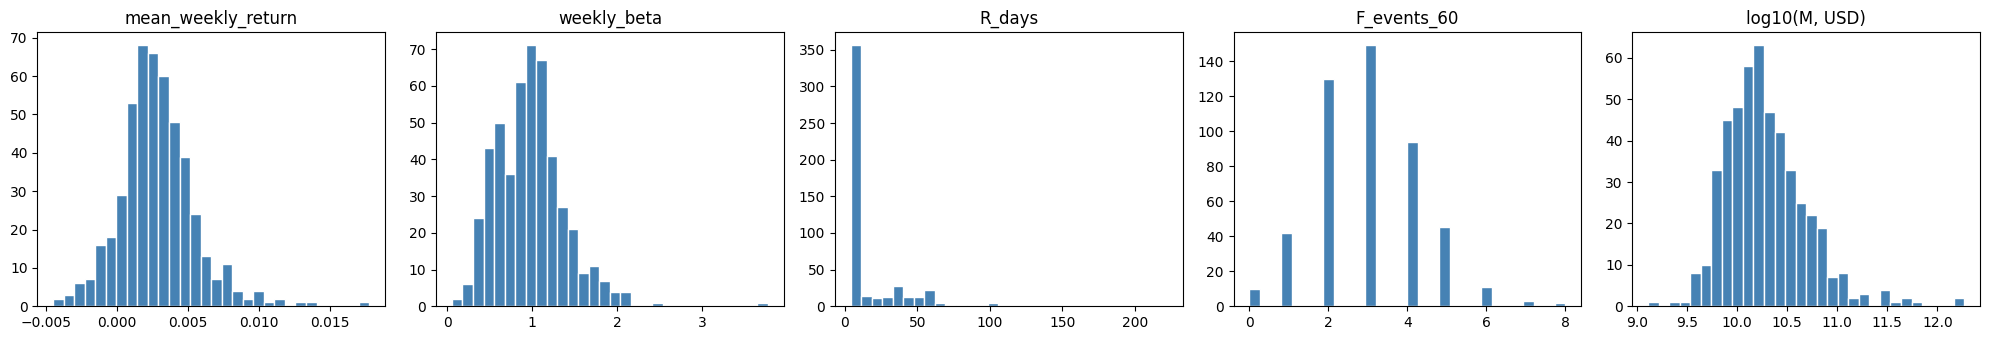

In [16]:
# 1.5b  Feature summaries
cols = ["mean_weekly_return", "weekly_beta", "R_days", "F_events_60", "M_traded_value_usd"]
summary = features.loc[features["in_common_set"], cols].describe(percentiles=[0.25, 0.5, 0.75]).T
summary["skew"] = features.loc[features["in_common_set"], cols].skew()
summary.to_csv("outputs/feature_summary.csv")
print(summary.round(4).to_string())

# Histograms of the five features (M on a log scale because it's very skewed)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
data = features.loc[features["in_common_set"]]
for ax, col in zip(axes, cols):
    vals = np.log10(data[col]) if col == "M_traded_value_usd" else data[col]
    ax.hist(vals, bins=30, color="steelblue", edgecolor="white")
    ax.set_title("log10(M, USD)" if col == "M_traded_value_usd" else col)
plt.tight_layout()
plt.savefig("figures/fig1_feature_distributions.png", dpi=150)
plt.show()

In [17]:
# 1.5c  Save metadata and print every number needed for the report
meta.update({
    "package_versions": versions,
    "n_tickers_in_list": len(tickers),
    "n_included": len(included),
    "n_excluded": len(exclusion_log),
    "n_common_set": int(features["in_common_set"].sum()),
    "weekly_returns_per_share": int(risk_return["n_weeks"].iloc[0]),
    "first_week_label": str(weekly_returns.index[0].date()),
    "last_week_label": str(weekly_returns.index[-1].date()),
    "rfm_window": f"{window_dates[0].date()} to {window_dates[-1].date()}",
})
json.dump(meta, open(META_FILE, "w"), indent=2, default=str)

ex_row = features.loc[EX]
sumc = features.loc[features["in_common_set"], cols]
report_numbers = {
    "Ticker retrieval date": meta["ticker_retrieval_date"],
    "Price download date": meta.get("price_download_date", "see metadata.json"),
    "Tickers in list": len(tickers),
    "Included / Excluded": f"{len(included)} / {len(exclusion_log)}",
    "Excluded - unequal history": int(exclusion_log["reason"].str.startswith("Unequal").sum()),
    "Excluded - other": int((~exclusion_log["reason"].str.startswith("Unequal")).sum()),
    "Trading days": len(calendar),
    "Removed incomplete weeks": ", ".join(str(x.date()) for x in dropped_weeks),
    "Weekly returns per share": int(risk_return["n_weeks"].iloc[0]),
    "First / last return week": f"{weekly_returns.index[0].date()} / {weekly_returns.index[-1].date()}",
    "Holiday-shortened weeks": int((trading_days_in_week < 5).sum()),
    "Shares with splits": int((inc["split_events"] > 0).sum()),
    "Observation date": str(OBS_DATE.date()),
    "60-session window": meta["rfm_window"],
    "No-event shares (R missing)": int(rfm["R_days"].isna().sum()),
    "Common valid set": int(features["in_common_set"].sum()),
    "Median mean weekly return %": round(sumc["mean_weekly_return"].median() * 100, 3),
    "Mean weekly return range %": f"{sumc['mean_weekly_return'].min()*100:.3f} to {sumc['mean_weekly_return'].max()*100:.3f}",
    "Median beta": round(sumc["weekly_beta"].median(), 2),
    "Beta range": f"{sumc['weekly_beta'].min():.2f} to {sumc['weekly_beta'].max():.2f}",
    "Median beta R2": round(features["beta_r2"].median(), 2),
    "Median beta SE": round(features["beta_se"].median(), 3),
    "Median R days": sumc["R_days"].median(),
    "Median F": sumc["F_events_60"].median(),
    "Share with F = 0 (%)": round((sumc["F_events_60"] == 0).mean() * 100, 1),
    "Median M ($bn)": round(sumc["M_traded_value_usd"].median() / 1e9, 2),
    "Max M ($bn) and ticker": f"{sumc['M_traded_value_usd'].max()/1e9:.1f} ({sumc['M_traded_value_usd'].idxmax()})",
    "Skew of M / log10 M": f"{sumc['M_traded_value_usd'].skew():.2f} / {np.log10(sumc['M_traded_value_usd']).skew():.2f}",
    "Worked example ticker": EX,
    f"{EX} mean weekly return %": round(ex_row["mean_weekly_return"] * 100, 3),
    f"{EX} beta (SE)": f"{ex_row['weekly_beta']:.2f} ({ex_row['beta_se']:.2f})",
    f"{EX} R / F / M($bn)": f"{ex_row['R_days']} / {ex_row['F_events_60']} / {ex_row['M_traded_value_usd']/1e9:.1f}",
}
for k, v in report_numbers.items():
    print(f"{k:32s}: {v}")
pd.Series(report_numbers).to_csv("outputs/report_numbers_task1.csv")

Ticker retrieval date           : 2026-11-21 06:47 UTC
Price download date             : 2026-11-21 06:48 UTC
Tickers in list                 : 503
Included / Excluded             : 486 / 17
Excluded - unequal history      : 10
Excluded - other                : 7
Trading days                    : 1005
Removed incomplete weeks        : 2025-01-03
Weekly returns per share        : 207
First / last return week        : 2021-01-15 / 2024-12-27
Holiday-shortened weeks         : 37
Shares with splits              : 53
Observation date                : 2024-12-31
60-session window               : 2024-10-07 to 2024-12-31
No-event shares (R missing)     : 0
Common valid set                : 486
Median mean weekly return %     : 0.262
Mean weekly return range %      : -0.447 to 1.777
Median beta                     : 0.95
Beta range                      : 0.06 to 3.78
Median beta R2                  : 0.28
Median beta SE                  : 0.101
Median R days                   : 11.0
Median F  

## 1.5d Supporting checks used in the report
Exclusion reasons, most common latest event dates, and the shares with extreme mean returns and betas.

In [18]:
# 1.5d  Supporting checks used in the report
# Exclusion log with reasons
print(exclusion_log[["Security", "reason"]].to_string())

# How many shares share the same latest high-volume day (shows the 20 Dec 2024 rebalancing effect)
print("\nMost common latest event dates:")
print(features["last_event_date"].value_counts().head(5))

# Extreme values, to confirm they are real shares and not data errors
cols2 = ["Security", "mean_weekly_return", "weekly_beta"]
print("\nHighest mean weekly return:\n", features.nlargest(3, "mean_weekly_return")[cols2])
print("\nHighest beta:\n", features.nlargest(3, "weekly_beta")[cols2])
print("\nLowest beta:\n", features.nsmallest(3, "weekly_beta")[cols2])

# Largest Close move on any split day (checks Close is split-adjusted)
print("\nMax |Close return| on split day:", validation_summary.iloc[7, 1])

                    Security                                                                          reason
Ticker                                                                                                      
APP                 AppLovin  Unequal history: first price 2021-04-15 (listed or spun off after study start)
COIN                Coinbase  Unequal history: first price 2021-04-14 (listed or spun off after study start)
CEG     Constellation Energy  Unequal history: first price 2022-01-19 (listed or spun off after study start)
EXE            Expand Energy  Unequal history: first price 2021-02-10 (listed or spun off after study start)
FDXF           FedEx Freight                   No price data in study period (listed or spun off after 2024)
FERG    Ferguson Enterprises                                          Volume error (zero or negative volume)
GEHC           GE HealthCare  Unequal history: first price 2022-12-15 (listed or spun off after study start)
GEV               G

## Report tables
Exports every Task 1 table used in the report to outputs/report_tables_task1.xlsx.

In [19]:
# Report tables: export every Task 1 table to one Excel file
# Table 1 - validation summary
t1 = validation_summary.rename(columns={"Check": "Validation check"})

# Table 2 - exclusion log
t2 = exclusion_log.reset_index()[["Ticker", "Security", "first_date", "reason"]].copy()
t2["first_date"] = pd.to_datetime(t2["first_date"]).dt.strftime("%Y-%m-%d").fillna("No data")
t2.columns = ["Ticker", "Company", "First price date", "Reason for exclusion"]

# Table 3 - weekly return and beta checks
t3 = pd.DataFrame({
    "Check": ["Weekly returns per share",
              f"{CHECK} first weekly return – manual calculation",
              f"{CHECK} first weekly return – notebook",
              "Max difference: resample vs groupby method",
              "Max difference: beta vs OLS slope",
              "Share and benchmark week labels identical",
              "All week labels exactly 7 days apart"],
    "Result": [int(risk_return["n_weeks"].iloc[0]),
               round(p[d2] / p[d1] - 1, 6),
               round(share_returns[CHECK].iloc[0], 6),
               f"{float((alt_returns - share_returns[CHECK]).abs().max()):.2e}",
               f"{float((beta_df['weekly_beta'] - slopes).abs().max()):.2e}",
               bool(share_returns.index.equals(market_returns.index)),
               bool((gaps == pd.Timedelta(days=7)).all())],
})

# Table 4a - worked RFM example summary
t4a = pd.DataFrame({
    "Item": ["Share", "Observation date", "60-session window", "Latest high-volume day",
             "Recency (calendar days)", "Frequency (high-volume days in window)", "Monetary (USD bn)"],
    "Value": [EX, str(OBS_DATE.date()), meta["rfm_window"],
              str(events_all.max().date()) if len(events_all) else "None",
              R_manual, F_manual, round(M_manual / 1e9, 1)],
})

# Table 4b - qualifying high-volume days inside the window
t4b = ex_win[ex_win["HighVolume"]].reset_index()
t4b = pd.DataFrame({
    "Date": t4b["Date"].dt.strftime("%Y-%m-%d"),
    "Close (USD)": t4b["Close"].round(2),
    "Volume": t4b["Volume"].map("{:,.0f}".format),
    "Mean volume previous 20 sessions": t4b["Baseline_prev20"].map("{:,.0f}".format),
    "Threshold (2x)": t4b["Threshold_2x"].map("{:,.0f}".format),
    "Traded value (USD bn)": (t4b["TradedValue"] / 1e9).round(2),
})

# Table 5 - feature summary in readable units
readable = features.loc[features["in_common_set"], cols].copy()
readable["mean_weekly_return"] *= 100
readable["M_traded_value_usd"] /= 1e9
readable.columns = ["Mean weekly return (%)", "Weekly beta", "Recency (days)",
                    "Frequency (days)", "Monetary (USD bn)"]
t5 = readable.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
t5["skew"] = readable.skew()
t5 = t5.round(3).reset_index().rename(columns={"index": "Feature", "50%": "median"})

# Appendix B - first 10 rows of the feature table
appB = features.head(10).reset_index()[["Ticker", "Security", "GICS Sector", "mean_weekly_return",
                                        "weekly_beta", "R_days", "F_events_60", "M_traded_value_usd"]].copy()
appB["mean_weekly_return"] = (appB["mean_weekly_return"] * 100).round(3)
appB["weekly_beta"] = appB["weekly_beta"].round(2)
appB["M_traded_value_usd"] = (appB["M_traded_value_usd"] / 1e9).round(2)
appB.columns = ["Ticker", "Company", "Sector", "Mean weekly return (%)", "Beta", "R (days)", "F", "M (USD bn)"]

# Appendix C - package versions and key metadata
appC = pd.DataFrame(list({**versions,
                          "ticker_retrieval_date": meta["ticker_retrieval_date"],
                          "price_download_date": meta.get("price_download_date", ""),
                          "study_period": f"{START} to {END} (end exclusive)",
                          "observation_date": str(OBS_DATE.date())}.items()),
                    columns=["Item", "Value"])

with pd.ExcelWriter("outputs/report_tables_task1.xlsx") as writer:
    for name, tbl in [("Table1_Validation", t1), ("Table2_Exclusions", t2), ("Table3_Checks", t3),
                      ("Table4a_RFM_example", t4a), ("Table4b_Qualifying_days", t4b),
                      ("Table5_Feature_summary", t5), ("AppendixB_Features", appB), ("AppendixC_Versions", appC)]:
        tbl.to_excel(writer, sheet_name=name, index=False)
print("Saved outputs/report_tables_task1.xlsx")

Saved outputs/report_tables_task1.xlsx
